In [2]:
import sys; sys.path.append("..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from src.utils import evaluate
df = pd.read_csv("../data/processed/delhi_pollution_weather_daily_2020_2025.csv",
                 parse_dates=["Date"]).sort_values("Date").reset_index(drop=True)
# regular daily index; missing days are NaN, NOT dropped
full_ts = df.set_index("Date")["PM2.5"].asfreq("D").astype(float)
train_ts = full_ts.loc["2020-01-01":"2023-12-31"]
val_ts= full_ts.loc["2024-01-01":"2024-12-31"]
test_ts = full_ts.loc["2025-01-01":"2025-12-31"]
for name, s in [("TRAIN", train_ts), ("VAL", val_ts), ("TEST", test_ts)]:
    print(name, s.index.min().date(), s.index.max().date(), len(s), "missing:", s.isna().sum())
train_observed = train_ts.dropna()

TRAIN 2020-01-01 2023-12-31 1461 missing: 50
VAL 2024-01-01 2024-12-31 366 missing: 3
TEST 2025-01-01 2025-12-31 365 missing: 9


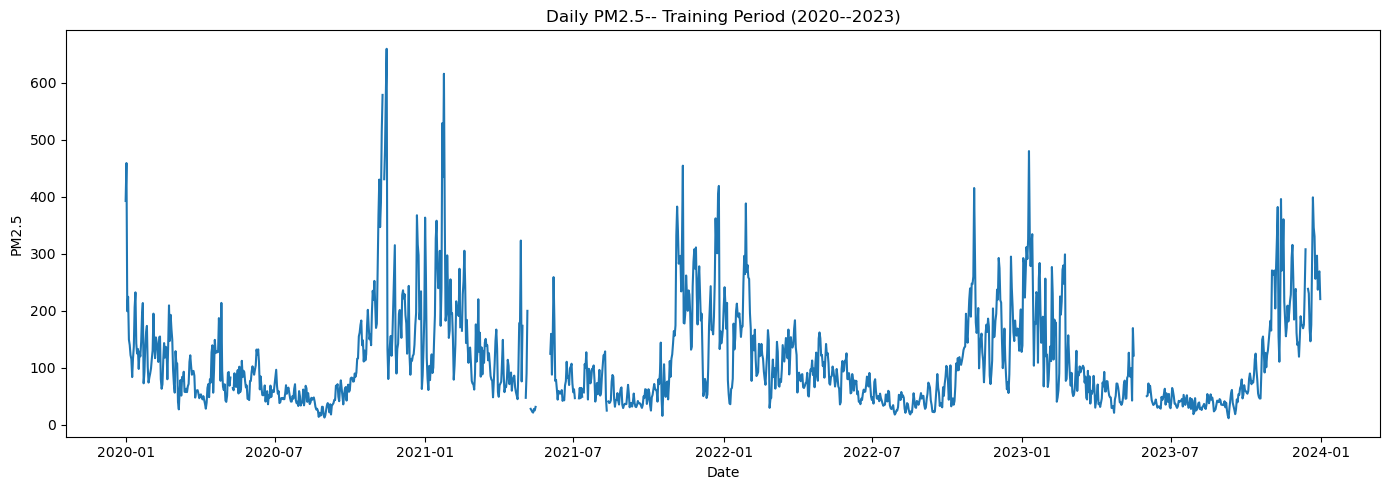

In [3]:
plt.figure(figsize=(14, 5))
plt.plot(train_ts)
plt.title("Daily PM2.5-- Training Period (2020--2023)")
plt.xlabel("Date"); plt.ylabel("PM2.5")
plt.tight_layout(); plt.show()

In [6]:
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
adf = adfuller(train_observed, autolag="AIC")
print("ADF statistic:", adf[0], " p-value:", adf[1])
for k, v in adf[4].items():
    print(f" {k}: {v:.3f}")
with warnings.catch_warnings():
    warnings.simplefilter("ignore") # KPSS p-value is table-truncated
    kp_stat, kp_p,_, kp_crit = kpss(train_observed, regression="c",nlags="auto")
print("KPSS statistic:", kp_stat, " p-value (truncated):", kp_p)

ADF statistic: -3.1929769590201853  p-value: 0.020394816464345617
 1%: -3.435
 5%: -2.864
 10%: -2.568
KPSS statistic: 0.10195238747924404  p-value (truncated): 0.1


In [9]:
d = 0 if adf[1] < 0.05 else 1
print("Chosen d=", d)
# differencingon the regular index:a gap yields NaN,never a fake 2-daydifference
analysis_series= (train_ts if d ==0 else train_ts.diff()).dropna()
if d == 1:
    print("DifferencedADF p-value:", adfuller(analysis_series)[1])

Chosen d= 0


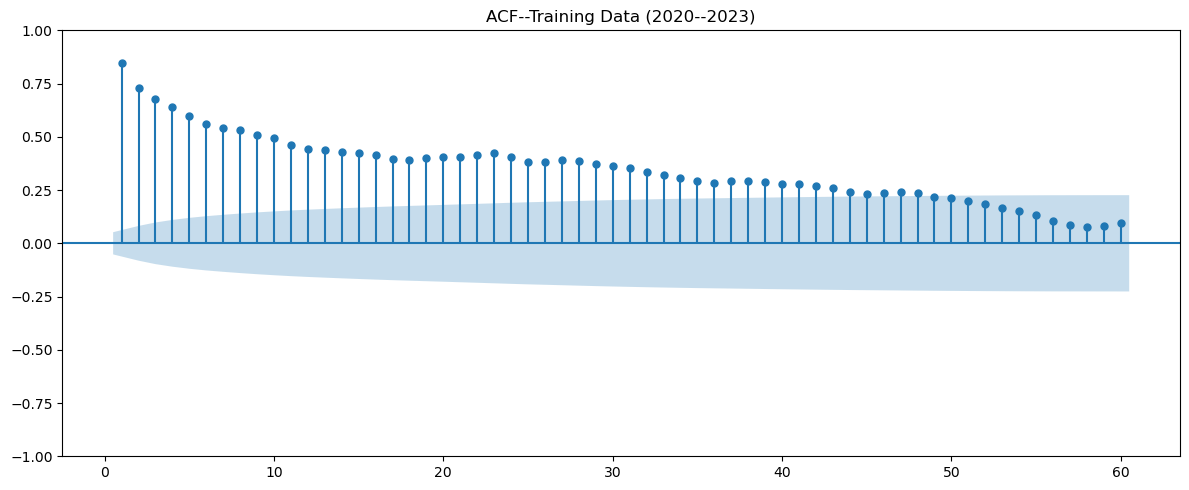

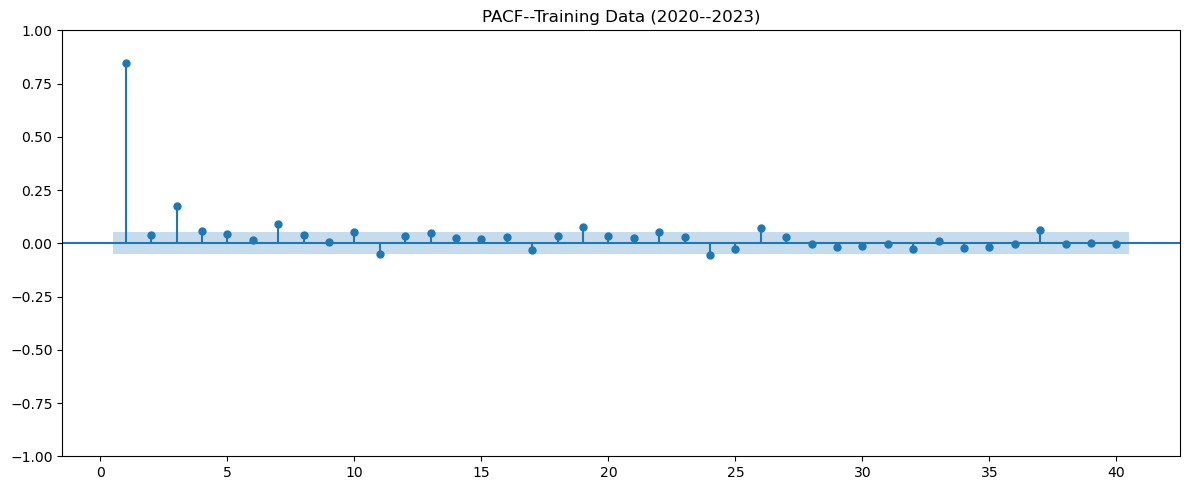

In [10]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, ax =plt.subplots(figsize=(12, 5))
plot_acf(analysis_series.to_numpy(), lags=60, ax=ax, zero=False)
ax.set_title("ACF--Training Data (2020--2023)")
plt.tight_layout();plt.show()
fig, ax =plt.subplots(figsize=(12, 5))
plot_pacf(analysis_series.to_numpy(), lags=40,ax=ax, zero=False, method="ywm")
ax.set_title("PACF--Training Data (2020--2023)")
plt.tight_layout();plt.show()

In [11]:
orders = [(1, d, 0), (2, d, 0), (3, d, 0), (1, d, 1), (2, d, 1), (2, d, 2)]

In [12]:
from statsmodels.tsa.arima.model import ARIMA
rows = []
for order in orders:
    fit = ARIMA(train_ts, order=order).fit()
# NaN days handled by the Kalman filter
    rows.append({"order": order, "AIC": fit.aic, "BIC": fit.bic})
aic_bic_df = pd.DataFrame(rows).sort_values("AIC")
display(aic_bic_df)

C:\Users\Dell\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\Dell\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


,order,AIC,BIC
5,"(2, 0, 2)",14703.817930,14735.539189
2,"(3, 0, 0)",14720.500047,14746.934429
3,"(1, 0, 1)",14757.131667,14778.279172
1,"(2, 0, 0)",14758.841961,14779.989467
0,"(1, 0, 0)",14759.449747,14775.310376
4,"(2, 0, 1)",14761.279364,14787.713746


In [14]:
from src.time_series import walk_forward_arima
val_series = full_ts.loc[:"2024-12-31"] # 2025 physically excluded
val_rows, val_preds = [], {}
for order in orders:
    pdf = walk_forward_arima(val_series, order,"2024-01-01", "2024-12-31")
    val_preds[order]= pdf
    val_rows.append({"order": order, **evaluate(pdf["Actual"], pdf["Predicted"])})
validation_results= pd.DataFrame(val_rows).sort_values("MAE")
display(validation_results)
# sanity benchmark: persistence on EXACTLY the same days
pers = full_ts.shift(1).loc["2024-01-01":"2024-12-31"]
print("Persistence(2024):", evaluate(val_ts,pers))

C:\Users\Dell\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\Dell\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
C:\Users\Dell\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\Dell\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
C:\Users\Dell\anaconda3\Lib\site-p

,order,MAE,RMSE,R2,n
5,"(2, 0, 2)",24.039150,38.032650,0.732596,363
2,"(3, 0, 0)",24.051826,37.928956,0.734052,363
3,"(1, 0, 1)",24.441984,37.798770,0.735875,363
1,"(2, 0, 0)",24.537908,38.058073,0.732238,363
0,"(1, 0, 0)",24.725477,38.512864,0.725801,363
4,"(2, 0, 1)",25.123352,39.149788,0.716656,363


Persistence(2024): {'MAE': 24.748201657458566, 'RMSE': 39.964954141857504, 'R2': 0.7045554907459296, 'n': 362}


In [15]:
def pick_simplest(res, tol=0.01):
    """Among modelswithin ‘tol‘ (1%) ofthe best MAE, takethe one with smallestp+q."""
    best = res["MAE"].min()
    ok = res[res["MAE"] <= best * (1+ tol)].copy()
    ok["k"] = ok["order"].apply(lambda o: o[0] + o[2])
    return ok.sort_values(["k", "MAE"]).iloc[0]["order"]
best_order = tuple(pick_simplest(validation_results))
print("SelectedARIMA order:", best_order)

SelectedARIMA order: (3, 0, 0)


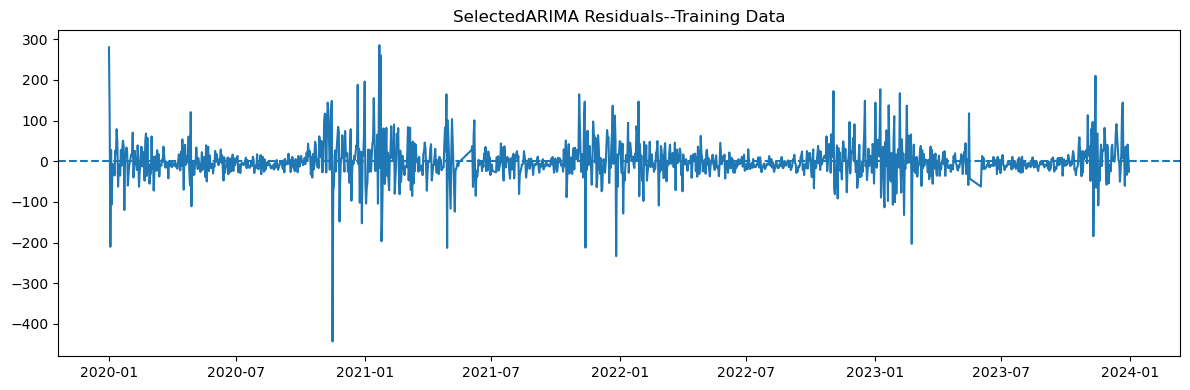

,lb_stat,lb_pvalue
10,25.130118,0.000720
20,32.564675,0.012791


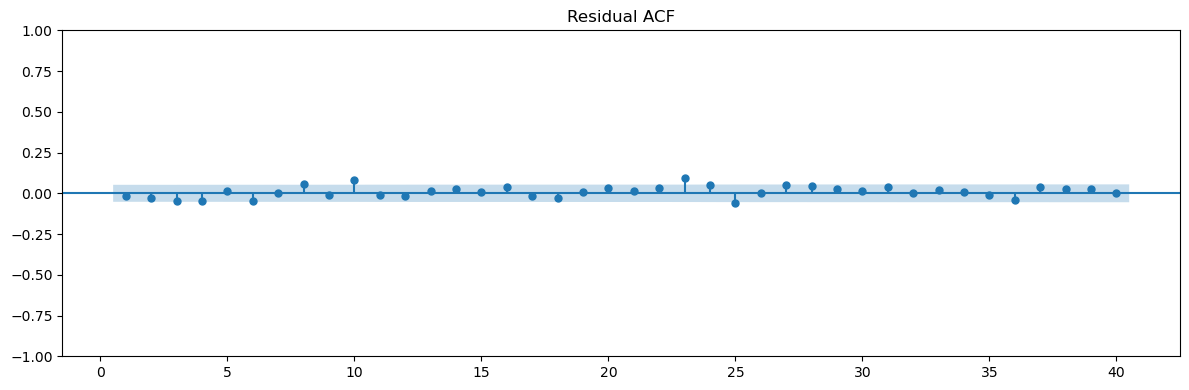

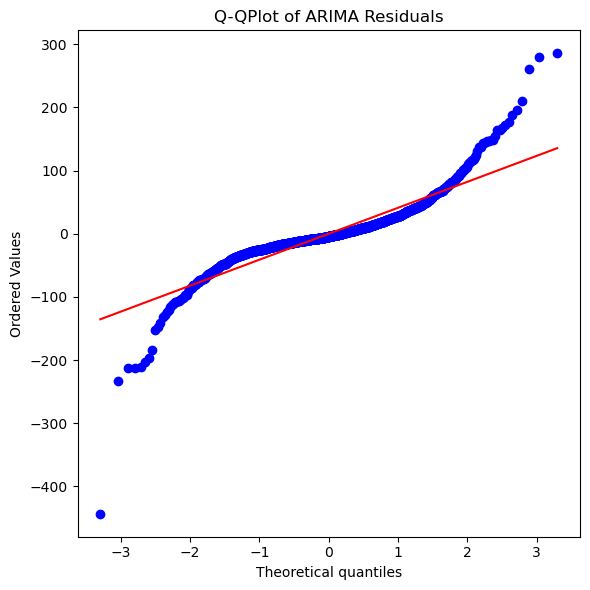

In [16]:
selected_fit =ARIMA(train_ts, order=best_order).fit()
residuals =selected_fit.resid.iloc[d:].dropna() # first dresiduals are artefacts
plt.figure(figsize=(12, 4))
plt.plot(residuals); plt.axhline(0, linestyle="--")
plt.title("SelectedARIMA Residuals--Training Data")
plt.tight_layout();plt.show()
from statsmodels.stats.diagnostic import acorr_ljungbox
p_, q_ =best_order[0], best_order[2]
lb = acorr_ljungbox(residuals, lags=[10,20], model_df=p_ + q_,return_df=True)
display(lb)
fig, ax =plt.subplots(figsize=(12, 4))
plot_acf(residuals.to_numpy(), lags=40, ax=ax,zero=False)
ax.set_title("Residual ACF"); plt.tight_layout(); plt.show()
import scipy.stats as stats
fig, ax =plt.subplots(figsize=(6, 6))
stats.probplot(residuals, dist="norm", plot=ax)
ax.set_title("Q-QPlot of ARIMA Residuals"); plt.tight_layout(); plt.show()

In [17]:
test_forecast =walk_forward_arima(full_ts,best_order, "2025-01-01", "2025-12-31")
print("Final ARIMA 2025:", evaluate(test_forecast["Actual"], test_forecast["Predicted"]))
pers_test =full_ts.shift(1).loc["2025-01-01":"2025-12-31"]
print("Persistence2025:", evaluate(test_ts,pers_test))
test_forecast.to_csv("../results/tables/arima_test_predictions.csv", index_label="Date")
val_preds[best_order].to_csv("../results/tables/arima_val_predictions.csv", index_label="Date")

Final ARIMA 2025: {'MAE': 22.732329823854485, 'RMSE': 33.67677102361109, 'R2': 0.8212704966668434, 'n': 356}
Persistence2025: {'MAE': 23.22830028328612, 'RMSE': 34.90197877049835, 'R2': 0.808503580270461, 'n': 353}


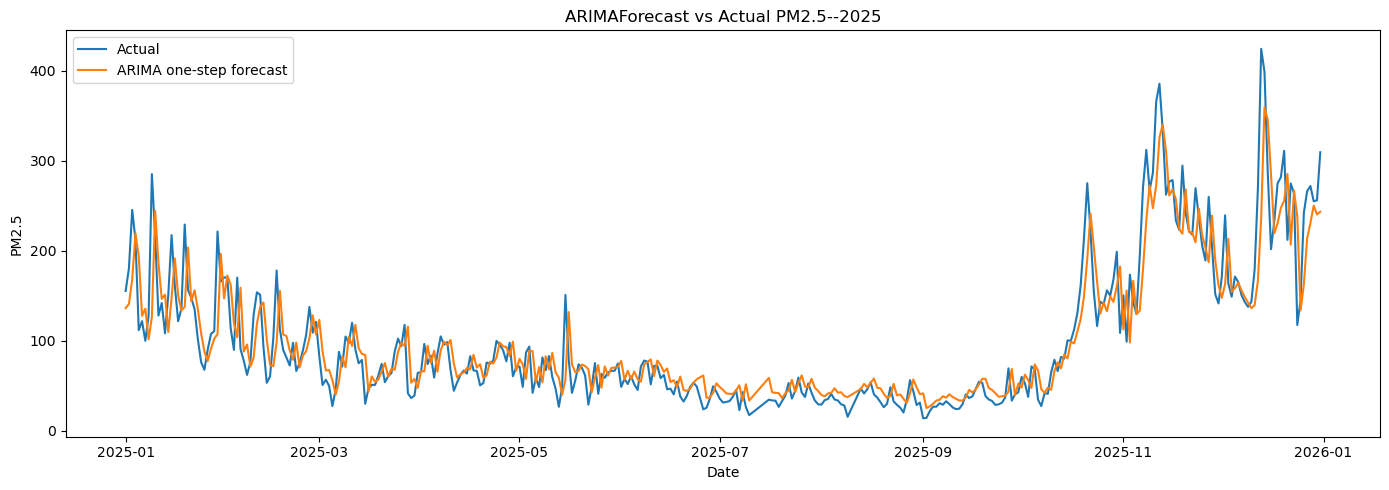

In [18]:
tv = test_forecast.dropna()
plt.figure(figsize=(14, 5))
plt.plot(tv.index,tv["Actual"], label="Actual")
plt.plot(tv.index,tv["Predicted"], label="ARIMA one-step forecast")
plt.title("ARIMAForecast vs Actual PM2.5--2025")
plt.xlabel("Date");plt.ylabel("PM2.5"); plt.legend()
plt.tight_layout();plt.show()

Leakage test passed.
